In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

In [ ]:
%%writefile sobel_processing.cpp


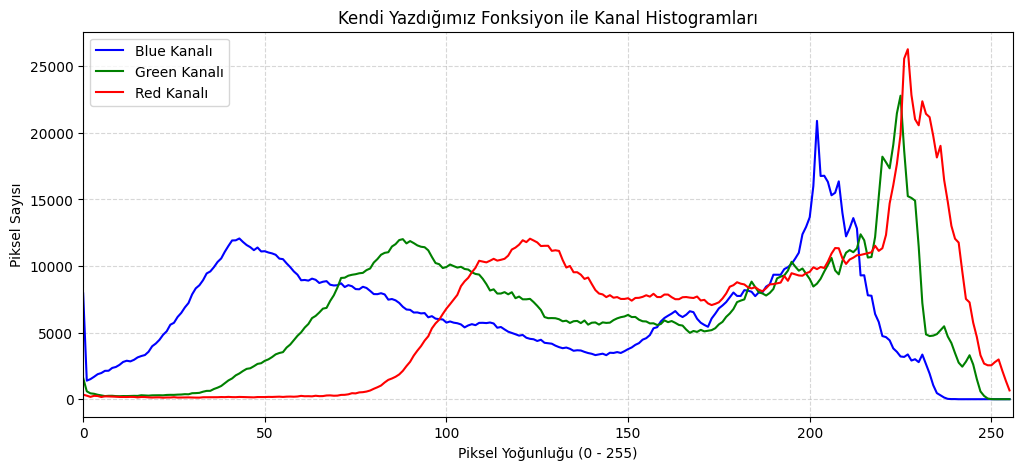

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Kendi histogram hesaplama fonksiyonumuz
def custom_calc_hist(channel_image):
    # 0'dan 255'e kadar her piksel değeri için bir sayaç dizisi oluşturuyoruz
    hist = np.zeros(256, dtype=np.int32)

    # Görüntünün her bir pikselini dolaşarak değerleri sayıyoruz
    for r in range(channel_image.shape[0]):
        for c in range(channel_image.shape[1]):
            pixel_value = channel_image[r, c]
            hist[pixel_value] += 1

    return hist

# Resmi tekrar yükleyelim (BGR formatında)
img_path = '/content/resimm.jpg.avif'
image = cv2.imread(img_path)

if image is None:
    print(f"Hata: {img_path} yolunda resim bulunamadı!")
else:
    channels = ('b', 'g', 'r')
    colors = ('blue', 'green', 'red')

    plt.figure(figsize=(12, 5))
    plt.title('Kendi Yazdığımız Fonksiyon ile Kanal Histogramları')
    plt.xlabel('Piksel Yoğunluğu (0 - 255)')
    plt.ylabel('Piksel Sayısı')

    # Her bir kanal için kendi fonksiyonumuzu çağırıyoruz
    for i, col in enumerate(channels):
        # İlgili kanalı dilimliyoruz (0: Mavi, 1: Yeşil, 2: Kırmızı)
        channel_data = image[:, :, i]

        # Kendi yazdığımız fonksiyonu kullanarak histogramı hesaplıyoruz
        my_hist = custom_calc_hist(channel_data)

        # Sonucu çizdiriyoruz
        plt.plot(my_hist, color=colors[i], label=f'{colors[i].capitalize()} Kanalı')
        plt.xlim([0, 256])

    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()